# Chance level C vs I: epochs mínims i mapa temps×elèctrode

## Objectiu

Aquest notebook queda centrat en 3 preguntes:
1. Quants epochs calen (aprox.) per superar el chance level en C vs I?
2. Per a cada elèctrode, a partir de quin instant se supera chance level?
3. A nivell de grup, on i quan podem afirmar que l'accuracy supera chance?

Metodologia resumida:
- Model surrogate per subjecte/elèctrode/finestra amb permutació d'etiquetes.
- Definició de $\Delta Acc = Acc_{real} - Acc_{chance}$.
- Grup: contrast parellat entre $Acc_{real}$ i $Acc_{chance}$ per cel·la temps×elèctrode.

In [ ]:
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
%pip install -q mne
import mne
import numpy as np
import pandas as pd
from scipy.stats import ttest_rel
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    from google.colab import drive

    IN_COLAB = True
except ImportError:
    drive = None
    IN_COLAB = False

warnings.filterwarnings("ignore", category=RuntimeWarning)
mne.set_log_level("WARNING")

if IN_COLAB:
    BASE_DIR = Path("/content/drive/MyDrive/TFG_Nils_2026")
    DATA_DIR = BASE_DIR / "02_Data" / "01_Preprocessed_epochs"
else:
    BASE_DIR = Path(r"c:/Users/nils/Documents/Universitat/TFG")
    DATA_DIR = BASE_DIR / "data"

DATA_FILES = sorted(DATA_DIR.glob("*.fif"))
COND_EVENTS = {
    "Congruent": ["event_1", "event_2"],
    "Incongruent": ["event_3", "event_4", "event_5", "event_6", "event_7", "event_8"],
}

# Configuracio principal del chance-level
TASK_TAG = "c_vs_i"
ANALYSIS_WINDOW = (0.0, 1.5)
CHANNEL_MODE = "all_channels"  # "all_channels" o llista de canals
MAP_WINDOW_SEC = 0.25
MAP_STEP_SEC = 0.10
MAP_CV_MAX_SPLITS = 5
N_PERM_SURROGATE = 200
N_REPEATS_EPOCHS = 40
MIN_TRIALS_PER_CLASS = 12
RANDOM_SEED = 42

# Per estimar quants epochs calen (n total, balancejat C/I)
EPOCHS_GRID = [24, 32, 40, 48, 56, 64, 80, 96, 120, 160, 200]

print(f"Entorn: {'Colab' if IN_COLAB else 'Local'}")
print(f"Fitxers .fif trobats: {len(DATA_FILES)}")
print("Configuració de chance level carregada.")

Entorn: Colab
Fitxers .fif trobats: 0
Configuracio de chance level carregada.


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Preprocessament centralitzat a: /content/drive/MyDrive/TFG_Nils_2026/03_Codi/01_preprocessament.ipynb
Mostres totals: 22860
C: 8471 | I: 14389
Subjectes inclosos: 47
Dimensió features: (22860, 216)
ICA_COMPONENTS recomanat (màxim): 20
Dataset desat a: /content/drive/MyDrive/TFG_Nils_2026/02_Data/01_Preprocessed_epochs/processed/c_vs_i_fcz_theta_oz_alpha_stft.npz
Resum per subjecte desat a: /content/drive/MyDrive/TFG_Nils_2026/02_Data/01_Preprocessed_epochs/processed/c_vs_i_subject_summary.csv


,subject,n_trials,n_c,n_i,n_ip,n_im,n_features
0,P0002,384,144,240,133,107,216
1,P0003,501,191,310,193,117,216
2,P0004,586,218,368,65,303,216
3,P0005,456,166,290,121,169,216
4,P0009,581,224,357,121,236,216
5,P008,248,90,158,58,100,216
6,P010,623,247,376,157,219,216
7,P011,431,121,310,162,148,216
8,P013,577,225,352,159,193,216
9,P014,406,127,279,69,210,216


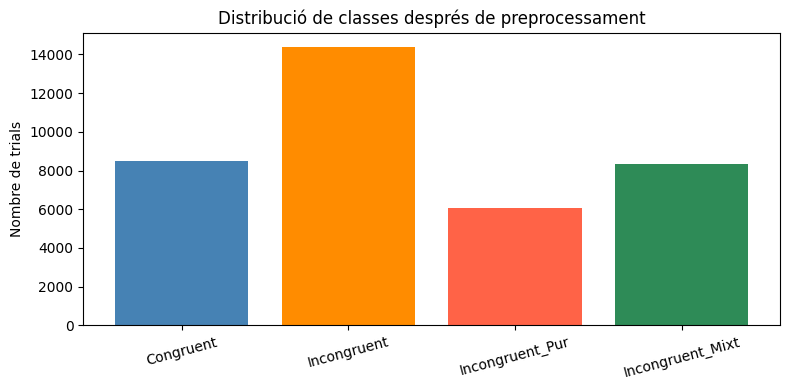

Preprocessament completat. Carregant dataset processat...
Dataset carregat de: /content/drive/MyDrive/TFG_Nils_2026/02_Data/01_Preprocessed_epochs/processed/c_vs_i_fcz_theta_oz_alpha_stft.npz
Mostres totals: 22860
Congruent (0): 8471 | Incongruent (1): 14389
Subjectes inclosos: 47
Matriu de caracteristiques: (22860, 216)
Components ICA maxims: 20
Counts -> C: 8471 | I: 14389 | I pur: 6075 | I mixt: 8314


In [ ]:
if IN_COLAB and drive is not None:
    drive.mount("/content/drive", force_remount=False)


def _channel_tag(ch_names):
    if CHANNEL_MODE == "all_channels":
        return "all_channels"
    if len(ch_names) <= 4:
        return "-".join(ch_names).lower()
    return f"{len(ch_names)}ch"


def load_chance_epochs():
    X_blocks, y_blocks, subj_blocks = [], [], []
    ch_ref = None
    times_ref = None
    skipped = []

    for fif_path in DATA_FILES:
        ep = mne.read_epochs(fif_path, preload=True, verbose=False)
        ep.set_channel_types({ch: "eeg" for ch in ep.ch_names}, on_unit_change="ignore")

        c_names = [n for n in COND_EVENTS["Congruent"] if n in ep.event_id]
        i_names = [n for n in COND_EVENTS["Incongruent"] if n in ep.event_id]
        if not c_names or not i_names:
            skipped.append(f"{fif_path.name}: sense C o I")
            continue

        ep = ep[c_names + i_names].copy().crop(tmin=ANALYSIS_WINDOW[0], tmax=ANALYSIS_WINDOW[1])
        if CHANNEL_MODE != "all_channels":
            missing = [ch for ch in CHANNEL_MODE if ch not in ep.ch_names]
            if missing:
                skipped.append(f"{fif_path.name}: falten canals {missing}")
                continue
            ep.pick(CHANNEL_MODE)

        events = ep.events[:, 2]
        c_codes = [ep.event_id[n] for n in c_names]
        y = np.where(np.isin(events, c_codes), 0, 1).astype(np.int8)

        # Subjectes amb massa pocs trials no son fiables per CV
        n_c = int(np.sum(y == 0))
        n_i = int(np.sum(y == 1))
        if min(n_c, n_i) < MIN_TRIALS_PER_CLASS:
            skipped.append(f"{fif_path.name}: pocs trials per classe (C={n_c}, I={n_i})")
            continue

        X_subj = ep.get_data().astype(np.float32, copy=False)  # trials x channels x times

        if ch_ref is None:
            ch_ref = ep.ch_names
            times_ref = ep.times
        else:
            if ep.ch_names != ch_ref or len(ep.times) != len(times_ref):
                skipped.append(f"{fif_path.name}: canals/temps incompatibles")
                continue

        X_blocks.append(X_subj)
        y_blocks.append(y)
        subj_blocks.extend([fif_path.stem] * len(y))

    if not X_blocks:
        raise RuntimeError("No hi ha dades suficients per a l'analisi de chance level.")

    X = np.concatenate(X_blocks, axis=0)
    y = np.concatenate(y_blocks, axis=0)
    subj_list = np.array(subj_blocks, dtype=object)
    ch_names = list(ch_ref)
    times = np.array(times_ref, dtype=np.float32)

    channel_tag = _channel_tag(ch_names)
    w_tag = f"{int(ANALYSIS_WINDOW[0]*1000)}-{int(ANALYSIS_WINDOW[1]*1000)}ms"
    dataset_name = f"{TASK_TAG}_{channel_tag}_{w_tag}_chance_tensor.npz"

    out_dir = DATA_DIR / "processed" / "chance"
    out_dir.mkdir(parents=True, exist_ok=True)
    dataset_path = out_dir / dataset_name

    np.savez_compressed(
        dataset_path,
        X=X,
        y=y,
        subj_list=subj_list.astype(str),
        ch_names=np.array(ch_names, dtype=object),
        times=times,
        analysis_window=np.array(ANALYSIS_WINDOW, dtype=np.float32),
        task_tag=np.array(TASK_TAG, dtype=object),
        channel_mode=np.array(channel_tag, dtype=object),
        map_window_sec=np.float32(MAP_WINDOW_SEC),
        map_step_sec=np.float32(MAP_STEP_SEC),
    )

    print(f"Dataset chance desat a: {dataset_path}")
    print(f"Mostres totals: {len(y)} | C={(y==0).sum()} | I={(y==1).sum()}")
    print(f"Subjectes inclosos: {len(np.unique(subj_list))} | Canals: {len(ch_names)} | Temps: {len(times)}")
    if skipped:
        print("Subjectes omesos:")
        for msg in skipped:
            print(f"  - {msg}")

    return X, y, subj_list, ch_names, times


X, y, subj_list, ch_names, times = load_chance_epochs()

## Funcions d'avaluació (cross-validation i surrogate chance)

Aquest bloc defineix:
- selecció automàtica de nombre de folds segons mida de mostra,
- accuracy real per CV,
- baseline surrogate per permutació de labels,
- i $\Delta Acc = Acc_{real} - Acc_{chance}$.

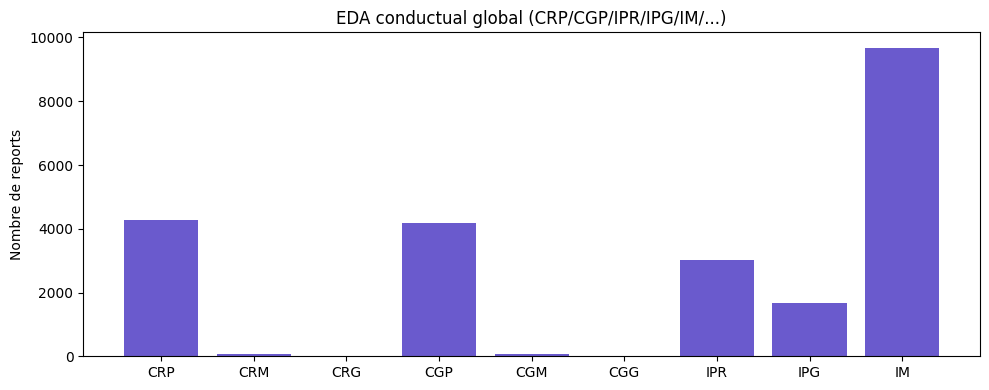

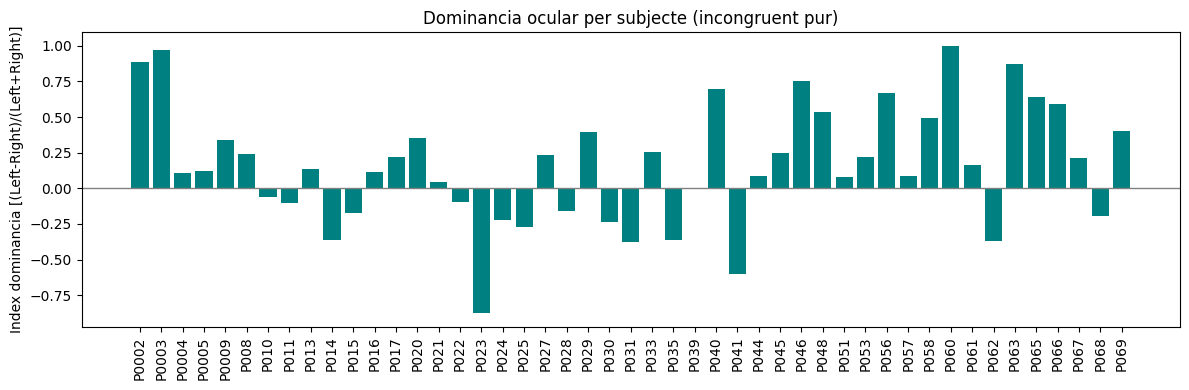

Resum conductual global:
  CRP :  4276
  CRM :    73
  CRG :    22
  CGP :  4195
  CGM :    77
  CGG :    17
  IPR :  3010
  IPG :  1679
  IM  :  9678

Dominancia ocular global (incongruent pur):
  Left-eye coherent : 2796
  Right-eye coherent: 1893
  Index global      : 0.193  (positiu = tendencia ull esquerre)


In [ ]:
def choose_n_splits(y, max_splits=5):
    class_counts = np.bincount(y)
    min_class = int(class_counts.min())
    return max(2, min(max_splits, min_class))


def cv_accuracy(X_feat, y, n_splits, random_seed=42):
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_seed)
    model = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis())
    fold_acc = []

    for train_idx, test_idx in cv.split(X_feat, y):
        model.fit(X_feat[train_idx], y[train_idx])
        y_pred = model.predict(X_feat[test_idx])
        fold_acc.append(float(np.mean(y_pred == y[test_idx])))

    fold_acc = np.array(fold_acc, dtype=np.float32)
    return float(np.mean(fold_acc)), fold_acc


def surrogate_stats(X_feat, y, n_splits, n_perm=200, random_seed=42):
    real_acc, _ = cv_accuracy(X_feat, y, n_splits=n_splits, random_seed=random_seed)
    rng = np.random.default_rng(random_seed)
    perm_acc = np.empty(n_perm, dtype=np.float32)

    for p in range(n_perm):
        y_perm = rng.permutation(y)
        perm_acc[p], _ = cv_accuracy(X_feat, y_perm, n_splits=n_splits, random_seed=random_seed + p + 1)

    chance_mean = float(np.mean(perm_acc))
    chance_q95 = float(np.quantile(perm_acc, 0.95))
    p_value = float((1 + np.sum(perm_acc >= real_acc)) / (n_perm + 1))

    return {
        "real_acc": real_acc,
        "chance_mean": chance_mean,
        "chance_q95": chance_q95,
        "delta_acc": float(real_acc - chance_mean),
        "p_perm": p_value,
        "perm_acc": perm_acc,
    }


def balanced_sample_indices(y, n_total, rng):
    n_per_class = n_total // 2
    idx_c = np.where(y == 0)[0]
    idx_i = np.where(y == 1)[0]
    if len(idx_c) < n_per_class or len(idx_i) < n_per_class:
        return None
    pick_c = rng.choice(idx_c, size=n_per_class, replace=False)
    pick_i = rng.choice(idx_i, size=n_per_class, replace=False)
    out = np.concatenate([pick_c, pick_i])
    rng.shuffle(out)
    return out


print("Funcions de CV i surrogate carregades.")

In [2]:
# 1) Quants epochs calen per superar chance? (estimació global)
rng = np.random.default_rng(RANDOM_SEED)
X_global = X.reshape(X.shape[0], -1)
y_global = y.copy()

n_splits_global = choose_n_splits(y_global, max_splits=MAP_CV_MAX_SPLITS)
print(f"CV global seleccionat: StratifiedKFold(n_splits={n_splits_global})")

rows = []
for n_total in EPOCHS_GRID:
    if n_total % 2 != 0:
        continue

    real_samples = []
    valid = 0

    for _ in range(N_REPEATS_EPOCHS):
        idx = balanced_sample_indices(y_global, n_total=n_total, rng=rng)
        if idx is None:
            continue
        real_acc, _ = cv_accuracy(
            X_global[idx], y_global[idx], n_splits=n_splits_global, random_seed=RANDOM_SEED + valid
        )
        real_samples.append(real_acc)
        valid += 1

    if valid == 0:
        continue

    # Surrogate sobre una mostra representativa balancejada d'aquesta mida
    idx_ref = balanced_sample_indices(y_global, n_total=n_total, rng=rng)
    if idx_ref is None:
        continue

    surrogate = surrogate_stats(
        X_global[idx_ref],
        y_global[idx_ref],
        n_splits=n_splits_global,
        n_perm=N_PERM_SURROGATE,
        random_seed=RANDOM_SEED + n_total,
    )

    rows.append(
        {
            "n_epochs_total": int(n_total),
            "n_repeats_real": int(valid),
            "acc_real_mean": float(np.mean(real_samples)),
            "acc_real_std": float(np.std(real_samples)),
            "acc_chance_mean": surrogate["chance_mean"],
            "acc_chance_q95": surrogate["chance_q95"],
            "delta_acc_mean": float(np.mean(real_samples) - surrogate["chance_mean"]),
        }
    )

df_epochs = pd.DataFrame(rows).sort_values("n_epochs_total").reset_index(drop=True)
display(df_epochs)

mask_surpass = df_epochs["acc_real_mean"] > df_epochs["acc_chance_q95"]
if mask_surpass.any():
    min_epochs_to_surpass = int(df_epochs.loc[mask_surpass, "n_epochs_total"].iloc[0])
    print(f"Epochs mínims estimats per superar chance (q95): {min_epochs_to_surpass}")
else:
    min_epochs_to_surpass = None
    print("No s'observa superació robusta de chance en el rang d'epochs provat.")

plt.figure(figsize=(8, 4))
plt.plot(df_epochs["n_epochs_total"], df_epochs["acc_real_mean"], marker="o", label="Acc real (mitjana)")
plt.plot(df_epochs["n_epochs_total"], df_epochs["acc_chance_q95"], marker="s", label="Chance q95 (surrogate)")
plt.fill_between(
    df_epochs["n_epochs_total"],
    df_epochs["acc_real_mean"] - df_epochs["acc_real_std"],
    df_epochs["acc_real_mean"] + df_epochs["acc_real_std"],
    alpha=0.2,
    label="±1 SD real",
)
plt.axhline(0.5, linestyle="--", color="gray", linewidth=1, label="Chance teòric (0.5)")
plt.xlabel("Nombre total d'epochs (balancejat)")
plt.ylabel("Accuracy")
plt.title("Corba d'epochs necessaris per superar chance")
plt.legend()
plt.tight_layout()
plt.show()

NameError: name 'np' is not defined

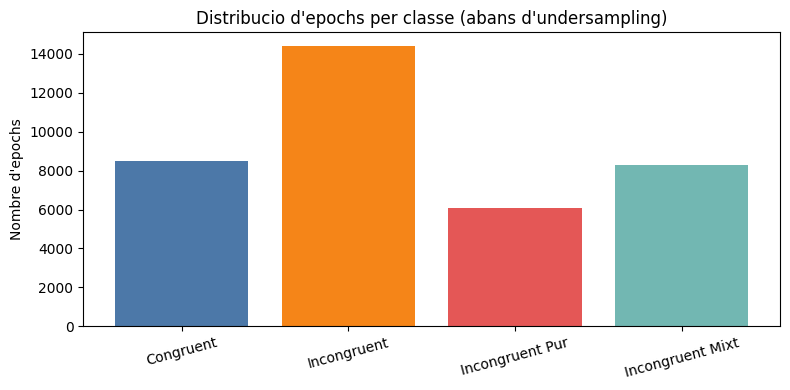

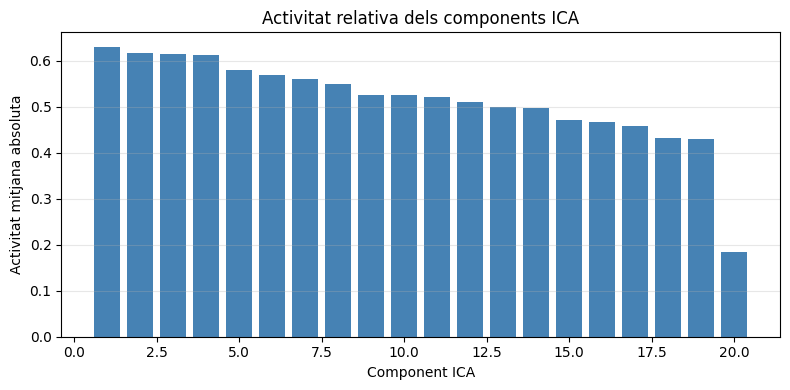

Components ICA disponibles: 20
Suggeriment automatic de components ICA: 19
Si vols forcar-ho manualment: ICA_COMPONENTS_SELECTED = <valor>


In [ ]:
# 2) Mapa temps×elèctrode + 3) contrast de grup
subjects = np.unique(subj_list)
n_subj = len(subjects)
n_ch = len(ch_names)

time_step = float(np.median(np.diff(times)))
sfreq_est = 1.0 / time_step
win_samples = max(2, int(round(MAP_WINDOW_SEC * sfreq_est)))
step_samples = max(1, int(round(MAP_STEP_SEC * sfreq_est)))
starts = np.arange(0, len(times) - win_samples + 1, step_samples)
stops = starts + win_samples
window_centers = np.array([times[s:e].mean() for s, e in zip(starts, stops)], dtype=np.float32)
n_w = len(window_centers)

real_map = np.full((n_subj, n_ch, n_w), np.nan, dtype=np.float32)
chance_mean_elec = np.full((n_subj, n_ch), np.nan, dtype=np.float32)
chance_q95_elec = np.full((n_subj, n_ch), np.nan, dtype=np.float32)

for si, subj in enumerate(subjects):
    idx_s = np.where(subj_list == subj)[0]
    Xs = X[idx_s]  # trials x channels x times
    ys = y[idx_s]

    if len(np.unique(ys)) < 2:
        continue

    n_splits_subj = choose_n_splits(ys, max_splits=MAP_CV_MAX_SPLITS)

    for ch_idx in range(n_ch):
        X_ch_full = Xs[:, ch_idx, :]  # trials x times

        # Surrogate per subjecte i elèctrode (baseline de chance empíric)
        sur = surrogate_stats(
            X_ch_full,
            ys,
            n_splits=n_splits_subj,
            n_perm=N_PERM_SURROGATE,
            random_seed=RANDOM_SEED + 1000 * (si + 1) + ch_idx,
        )
        chance_mean_elec[si, ch_idx] = sur["chance_mean"]
        chance_q95_elec[si, ch_idx] = sur["chance_q95"]

        # Accuracy real per finestra temporal
        for wi, (s, e) in enumerate(zip(starts, stops)):
            X_feat = X_ch_full[:, s:e].mean(axis=1, keepdims=True)
            real_acc, _ = cv_accuracy(
                X_feat,
                ys,
                n_splits=n_splits_subj,
                random_seed=RANDOM_SEED + wi + 10000 * (si + 1),
            )
            real_map[si, ch_idx, wi] = real_acc

delta_map = real_map - chance_mean_elec[:, :, None]
subj_above_q95 = real_map > chance_q95_elec[:, :, None]

# Test estadistic de grup (paired t-test: real vs chance_mean)
p_map = np.full((n_ch, n_w), np.nan, dtype=np.float32)
t_map = np.full((n_ch, n_w), np.nan, dtype=np.float32)
mean_delta_map = np.nanmean(delta_map, axis=0)
hit_rate_map = np.nanmean(subj_above_q95, axis=0)

for ch_idx in range(n_ch):
    for wi in range(n_w):
        a = real_map[:, ch_idx, wi]
        b = chance_mean_elec[:, ch_idx]
        valid = ~np.isnan(a) & ~np.isnan(b)
        if valid.sum() < 6:
            continue
        t_stat, p_val = ttest_rel(a[valid], b[valid])
        t_map[ch_idx, wi] = float(t_stat)
        p_map[ch_idx, wi] = float(p_val)

sig_map = (p_map < 0.05) & (mean_delta_map > 0)

# Temps d'onset per elèctrode (primer instant significatiu)
onset_time_per_ch = np.full(n_ch, np.nan, dtype=np.float32)
for ch_idx in range(n_ch):
    sig_idx = np.where(sig_map[ch_idx])[0]
    if len(sig_idx) > 0:
        onset_time_per_ch[ch_idx] = float(window_centers[sig_idx[0]])

print(f"Subjectes analitzats al mapa: {n_subj}")
print(f"Canals: {n_ch} | Finestres temporals: {n_w}")
print("Mapa de metrics calculat (real, chance surrogate, delta, p-valors).")

P0002 | epochs=384 | train 230->172 | ICA=19 | VAL F1=0.549 | TEST F1=0.509 | TEST ACC=0.532
P0003 | epochs=501 | train 300->228 | ICA=19 | VAL F1=0.597 | TEST F1=0.591 | TEST ACC=0.614
P0004 | epochs=586 | train 351->260 | ICA=19 | VAL F1=0.490 | TEST F1=0.558 | TEST ACC=0.576
P0005 | epochs=456 | train 273->200 | ICA=19 | VAL F1=0.480 | TEST F1=0.479 | TEST ACC=0.489
P0009 | epochs=581 | train 348->268 | ICA=19 | VAL F1=0.555 | TEST F1=0.492 | TEST ACC=0.530
P008 | epochs=248 | train 148->108 | ICA=19 | VAL F1=0.480 | TEST F1=0.495 | TEST ACC=0.500
P010 | epochs=623 | train 373->296 | ICA=19 | VAL F1=0.444 | TEST F1=0.552 | TEST ACC=0.552
P011 | epochs=431 | train 258->146 | ICA=19 | VAL F1=0.549 | TEST F1=0.436 | TEST ACC=0.517
P013 | epochs=577 | train 345->270 | ICA=19 | VAL F1=0.450 | TEST F1=0.495 | TEST ACC=0.500
P014 | epochs=406 | train 243->152 | ICA=19 | VAL F1=0.463 | TEST F1=0.412 | TEST ACC=0.427
P015 | epochs=405 | train 243->160 | ICA=19 | VAL F1=0.582 | TEST F1=0.609 

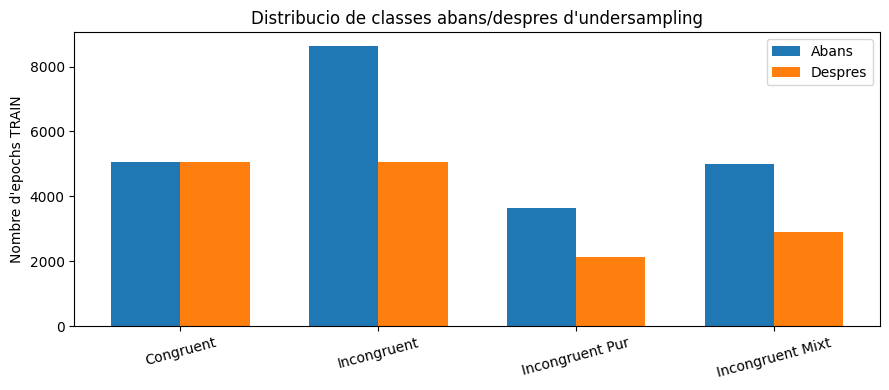

In [ ]:
# Visualitzacions i criteri de superacio a nivell de grup
electrode_order = np.array(ch_names, dtype=object)

# 1) Heatmap delta acc (canal x temps)
plt.figure(figsize=(12, 6))
im = plt.imshow(
    mean_delta_map,
    aspect="auto",
    origin="lower",
    extent=(float(window_centers[0]), float(window_centers[-1]), 0.0, float(len(electrode_order))),
    cmap="RdBu_r",
)
plt.colorbar(im, label="Delta Acc (real - chance_mean)")
yticks = np.arange(0, len(electrode_order), max(1, len(electrode_order) // 12))
yticklabels = [str(v) for v in electrode_order[yticks].tolist()]
plt.yticks(yticks + 0.5, yticklabels)
plt.xlabel("Temps (s)")
plt.ylabel("Elèctrode")
plt.title("Mapa grupal de ΔAcc")
plt.tight_layout()
plt.show()

# 2) Topomap de l'onset significatiu
info_topo = mne.create_info(list(electrode_order), sfreq=250.0, ch_types="eeg")
info_topo.set_montage("standard_1020", on_missing="ignore")

if np.isfinite(onset_time_per_ch).any():
    fig, ax = plt.subplots(figsize=(6, 5))
    mne.viz.plot_topomap(
        onset_time_per_ch,
        info_topo,
        axes=ax,
        show=False,
        cmap="viridis",
        vlim=(np.nanmin(onset_time_per_ch), np.nanmax(onset_time_per_ch)),
        mask=np.isfinite(onset_time_per_ch),
        mask_params=dict(markersize=5),
    )
    ax.set_title("Onset (s) de superació de chance per elèctrode")
    plt.show()
else:
    print("No hi ha elèctrodes amb onset significatiu en aquest setup.")

# 3) Resum temporal global
fraction_sig_electrodes = np.nanmean(sig_map, axis=0)
fraction_subjects_above_q95 = np.nanmean(hit_rate_map, axis=0)

plt.figure(figsize=(10, 4))
plt.plot(window_centers, fraction_sig_electrodes, label="Fracció elèctrodes significatius")
plt.plot(window_centers, fraction_subjects_above_q95, label="Hit-rate mig vs chance q95")
plt.axhline(0.2, linestyle="--", color="gray", linewidth=1, label="Llindar orientatiu 20%")
plt.xlabel("Temps (s)")
plt.ylabel("Proporció")
plt.title("Evolució temporal de la superació de chance (grup)")
plt.legend()
plt.tight_layout()
plt.show()

# Criteri pràctic de grup: p<0.05 + DeltaAcc>0 + hit-rate>=0.5
group_ok = sig_map & (hit_rate_map >= 0.5)
if np.any(group_ok):
    first_w = np.where(np.any(group_ok, axis=0))[0][0]
    first_time = float(window_centers[first_w])
    n_el = int(np.sum(group_ok[:, first_w]))
    print(f"Primer instant de superació grupal robusta: t={first_time:.3f}s ({n_el} elèctrodes)")
else:
    print("Amb el criteri robust (p<0.05, ΔAcc>0, hit-rate>=0.5) no hi ha superació clara.")

summary_rows = []
for ch_idx, ch in enumerate(electrode_order):
    summary_rows.append(
        {
            "electrode": ch,
            "onset_sec": onset_time_per_ch[ch_idx],
            "mean_delta_max": float(np.nanmax(mean_delta_map[ch_idx])),
            "max_hit_rate": float(np.nanmax(hit_rate_map[ch_idx])),
        }
    )
df_onset = pd.DataFrame(summary_rows).sort_values(["onset_sec", "mean_delta_max"], na_position="last")
display(df_onset.head(15))